In [1]:
! pip install langchain langchain-core langchain-cohere langchain-community

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 30.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 28.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 15.1 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [langchain-community]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
from google.colab import userdata
COHERE_API_KEY = userdata.get('COHERE_API_KEY')

In [3]:
import os
from langchain_cohere import ChatCohere

llm = ChatCohere(
    model="command-a-03-2025",
    cohere_api_key=COHERE_API_KEY
)

response = llm.invoke(
    "What is GenAI answer me in 3 words"
)
print(response.content)


Generative Artificial Intelligence.


In [ ]:
# Tool
# embedding
# RAG

# Recap
# -------
# prompt | llm ->invok({'':''})
# ------


# User ---<prompt>----> [ LLM ]
#      <--------------    ===  24th Oct 2024 //Cut-Off date
#   |
#  Q1: what is GenAI
#  Q2: explain about ML and DL
#  Q3: what is today 28th Oct 2026 USD ->INR - Websearch tool
#      ------------- ===========
#
# DuckDuckGoSearch - like Google
# ---------------
#  Search engine tool


In [4]:
! pip install ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 40.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [ddgs]


In [6]:
from langchain_community.tools import DuckDuckGoSearchRun

In [7]:
search = DuckDuckGoSearchRun()
search.invoke("what are the core updates in python 3.15?")

"Python 3.15 is the latest stable release of the Python programming language, with a mix of changes to the language, the implementation, and the standard library. Oct 9, 2026 · Python 3.15.0 is the newest major release of the Python programming language, and it contains many new features and optimisations compared to Python 3.14, in 5,643 commits from 1,012 contributors. The “What’s New in Python” series of essays takes tours through the most important changes between major Python versions. They are a “must read” for anyone wishing to stay up-to-date after a new release. Sep 30, 2026 · Learn what's new in Python 3.15, from lazy imports, frozendict, and sentinels to a sampling profiler and friendlier error messages. 3 days ago · Python 3.15.2 is an expedited security release and the second maintenance release of 3.15, containing around 130 bugfixes, build improvements and documentation changes from 70 contributors since 3.15.1."

In [8]:
search.invoke("what is the USD to INR exchanage rate on 28th Oct 2026")

"USD /INR bank rates, side by side. Today's US Dollar buy and sell quotes from every Indian bank in our cohort. TT, bills, travel card and currency-note channels, the mid-market benchmark and the per-bank spread, all in one place. Reference Rate Archive Search Reference Rate Select the Option All USD GBP EUR JPY AED IDR From Date To Date Back to previous page Last Updated On: Oct 27, 2026 US Dollar to Indian Rupee (USD/INR) exchange rate history for 2026 with daily rates, monthly averages, yearly high/low and historical chart. View 2026 exchange rate history between the Indian Rupee and the US Dollar. Accurate conversions, tables and charts with complete INR/USD history for 2026. HDFC Bank's buy and sell forex rates today, USD, EUR, GBP, AED and the full currency matrix. TT, bills, travel card and currency-note channels side by side, with one click to compare against every Indian bank."

In [9]:
search.invoke("what is the USD to INR exchanage rate on 28th Oct 2026")

"USD /INR bank rates, side by side. Today's US Dollar buy and sell quotes from every Indian bank in our cohort. TT, bills, travel card and currency-note channels, the mid-market benchmark and the per-bank spread, all in one place. US Dollar to Indian Rupee (USD/INR) exchange rate history for 2026 with daily rates, monthly averages, yearly high/low and historical chart. 1 USD To INR Convert United States Dollar To Indian Rupee 1 USD = 95.062122 INR Oct 28, 2026 03:32 UTC Check the currency rates against all the world currencies here. Reference Rate Archive Search Reference Rate Select the Option All USD GBP EUR JPY AED IDR From Date To Date Back to previous page Last Updated On: Oct 27, 2026 View 2026 exchange rate history between the Indian Rupee and the US Dollar. Accurate conversions, tables and charts with complete INR/USD history for 2026."

In [10]:
from langchain_cohere import ChatCohere
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.prompts import ChatPromptTemplate

from datetime import date

In [11]:
# Create LLM Object
llm = ChatCohere(
    model="command-a-03-2025",
    cohere_api_key=COHERE_API_KEY
)

# Create Search tool Object
search = DuckDuckGoSearchRun()


# Q1 - USD ->INR
user_question = "What is the USD to INR exchange rate on 28th October 2026?"

# Execute search tool - get the tool results
tool_search_result = search.invoke(user_question)

# Create Prompt Template
#
pobj = ChatPromptTemplate.from_messages([
    ('system',"""You are a financial information assistant.
    Answer using the search result only.
    Identify the exchange rate,currency pair,date and source
    If the results do not establish a reliable rate say so.Never invent a value """),
    ("human","""Question: {question}
     Search result:
     {search_result}
     Provide a concise answer.""")
])

# Create Chain  and Invoke the chain
chain = pobj | llm
response = chain.invoke({'question':user_question,"search_result": tool_search_result})

# Display Final Answer
#-----------------------------------
print(response.content)

**Exchange Rate:** ₹95.25 (mid-market rate) and ₹95.174244 (another source)  
**Currency Pair:** USD/INR  
**Date:** 28th October 2026  
**Source:** Not explicitly stated, but appears to be from a financial data provider or currency converter.  

Note: Two slightly different rates are provided, indicating a potential discrepancy or real-time fluctuation.


In [12]:
# Create LLM Object
llm = ChatCohere(
    model="command-a-03-2025",
    cohere_api_key=COHERE_API_KEY
)

# Create Search tool Object
search = DuckDuckGoSearchRun()


# Q1 - USD ->INR
user_question = "What is the USD to INR exchange rate on 28th October 2026?"

# Execute search tool - get the tool results
tool_search_result = search.invoke(user_question)

# Create Prompt Template
#
pobj = ChatPromptTemplate.from_messages([
    ('system',"""You are a AI Assistant.
    question is currency exchange
    Answer using the search result only.
    Identify the exchange rate,currency pair,date and source
    If the results do not establish a reliable rate then answer your own knowledge """),
    ("human","""Question: {question}
     Search result:
     {search_result}
     Provide a concise answer.""")
])

# Create Chain  and Invoke the chain
chain = pobj | llm
response1 = chain.invoke({'question':user_question,"search_result": tool_search_result})

# Display Final Answer
#-----------------------------------
print(response1.content)

**Exchange Rate:** 1 USD = ₹95.25 (mid-market rate)  
**Currency Pair:** USD/INR  
**Date:** 28 October 2026  
**Source:** Search result (Google mid-market rate)  

Note: Another source mentions 1 USD = ₹95.174244, but the mid-market rate of ₹95.25 is highlighted as the primary figure.


In [13]:
# Create Chain  and Invoke the chain
chain = pobj | llm
response2 = chain.invoke({'question':"what is AI explain in 5 words","search_result": tool_search_result})

# Display Final Answer
#-----------------------------------
print(response2.content)

**Exchange Rate:** 1 USD = ₹95.25 (mid-market rate)  
**Currency Pair:** USD/INR  
**Date:** October 28, 2026  
**Source:** Google (wholesale rate)  

Note: The search result does not answer the question about AI. Based on my knowledge, AI in 5 words is: **Artificial Intelligence automates human tasks.**


In [14]:
response2

AIMessage(content='**Exchange Rate:** 1 USD = ₹95.25 (mid-market rate)  \n**Currency Pair:** USD/INR  \n**Date:** October 28, 2026  \n**Source:** Google (wholesale rate)  \n\nNote: The search result does not answer the question about AI. Based on my knowledge, AI in 5 words is: **Artificial Intelligence automates human tasks.**', additional_kwargs={'id': '228cb3fd-1df0-48b9-8d5c-fd0a151ba69e', 'finish_reason': 'COMPLETE', 'token_count': {'input_tokens': 849.0, 'output_tokens': 93.0}}, response_metadata={'id': '228cb3fd-1df0-48b9-8d5c-fd0a151ba69e', 'finish_reason': 'COMPLETE', 'token_count': {'input_tokens': 849.0, 'output_tokens': 93.0}}, id='lc_run--01a180f3-5362-7556-b5b5-b7d68fb5d5f7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 849, 'output_tokens': 93, 'total_tokens': 942})

In [ ]:
#####
# Vector
# ---------
#  |->numerical array
#  | V = [10,20,30]
#         -----------// dim = 3
#
# 3D X,Y,Z

# Embedding - numerical representation of data(Text;Image;audio;video) - in a vector space
#

# "computer" --->[0.82,0.75]

# "dog" -------->[0.5,0.2]

# "laptop" ----->[0.84,0.77]

#  "cat" ------->[0.6,0.1]


In [15]:
! pip install sentence-transformers

In [16]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2") # pre-trained embedding model

text = "computer"

# Convert text into embedding vector
embedding = model.encode(text)
print(embedding)
print("Dims:",len(embedding))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[-5.12736253e-02  4.78383526e-02 -3.33909178e-03 -3.88702899e-02
 -3.26971151e-02 -3.28583419e-02  9.36042368e-02  3.93232591e-02
  8.19670632e-02  1.82483681e-02  9.45549365e-03 -5.94628649e-03
  2.97272056e-02 -2.62057222e-02 -4.12122756e-02 -3.62769738e-02
 -2.29891613e-02 -1.06736258e-01 -4.87580225e-02 -5.60849905e-02
 -4.75564301e-02 -8.35076254e-03 -8.10935870e-02  8.66687577e-03
 -3.06992035e-04  9.03218016e-02 -3.79807502e-02  1.68131932e-03
 -2.40882877e-02 -1.06959917e-01 -4.18318845e-02 -2.67985165e-02
  8.36226046e-02  1.78481508e-02 -5.06523848e-02 -2.39083022e-02
  4.05460447e-02 -2.48927753e-02  2.54598577e-02 -6.35695234e-02
 -1.92976259e-02 -6.59826538e-03  7.07030594e-02  2.32010502e-02
  5.63257299e-02  2.82638296e-02  1.91743281e-02 -3.77680128e-03
  4.69170660e-02  4.27727215e-02 -7.15216100e-02 -5.37855690e-03
 -7.01448973e-03  3.66113409e-02 -6.52935803e-02  3.59084085e-02
  3.99581753e-02  4.79450524e-02 -1.01777120e-02 -2.29346920e-02
 -1.56381708e-02 -6.07644

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

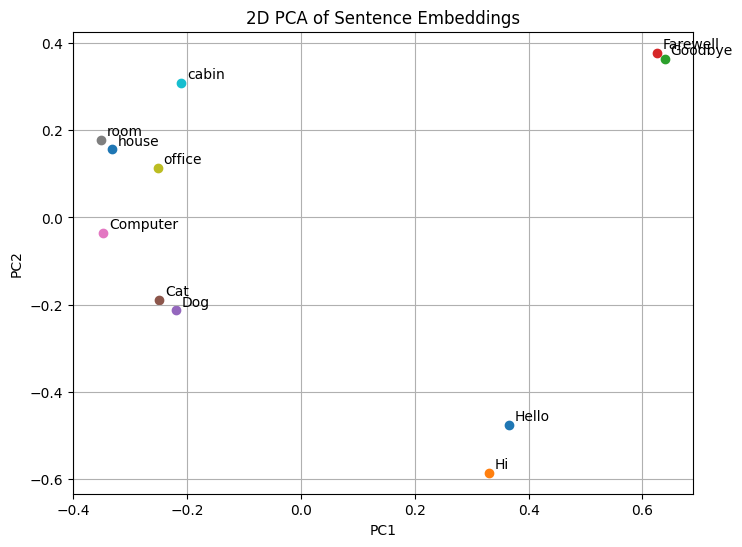

In [18]:
#from langchain_community.embeddings import OllamaEmbeddings
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Get embeddings for multiple queries
#embedding = OllamaEmbeddings(model='nomic-embed-text:latest')

model = SentenceTransformer("all-MiniLM-L6-v2")
sentences = ["Hello", "Hi", "Goodbye", "Farewell", "Dog", "Cat", "Computer","room","office",
             "cabin","house"]
vectors = [model.encode(s) for s in sentences]

# Reduce to 2D
pca = PCA(n_components=2)
reduced = pca.fit_transform(vectors)

# Plot
plt.figure(figsize=(8, 6))
for i, point in enumerate(reduced):
    plt.scatter(point[0], point[1])
    plt.text(point[0]+0.01, point[1]+0.01, sentences[i])
plt.title("2D PCA of Sentence Embeddings")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.show()

In [ ]:
## Retrieval Augmented Generation (RAG)
# -------------------------------------------
# RAG = Search our data + Give the results chunks to LLM + Generate an Answer
#
# User ---->[LLM] + [Tool-connect external world]
#  Vs

# HR Policy docs / logs / sales_report/ .. webSource .....
# ------------------------------------------------------------//Business data
#
# Data Loading (PDF/Excel/Folder/Logs/....)
#  |
# Split into chunks
#  |
# Embeddings - each chunk is converted to number - embedding (seamantic meaning)
#  |
# Vector Database
#  |
#  Retriever <-- User question
#  |
# Relevant chunks
#  |  + prompt
# LLM
#  |
# Answer


# 1. Data Loader -> [ metadata , page_content ]
#                      |                  |_______Actual Data
#                   info about loaded data

# 2. Split data into multiple chunks - ChunkSize,ChunkOverlap
#
# Ex: Chunksize = 3 ; ChunkOverlap is 1
# --------------------------------------------
# Chunk1 - [SentenceA] [SentenceB] [SentenceC]
# Chunk2 - [SentenceC] [SentenceD] [SentenceE]
# Chunk3 - [SentenceE] [SentenceF] [SentenceF]

# 3. Chunk1 ->embeddingModel ->[vectors]
#
# 4. Stores to VectorDB (FAISS,Chorma,Oracle23AI)
# ----------------------------------------------------//Indexing

# 5. similarity search

# ML is a subset of AI // docs
# -------------------------------->


# Similarity search -: explain about ML ------>      90%
#                      explain about factorial program ----> 2%
#

# 6. Create retriever object
# 7. Create LLM
# 8. Create prompt Object
# 9. Retriever QA Chain = Combine retrieverObject + LLM Object + PromptObject =>RAG Chain
# 10. RAGChain.invoke() ->response
#--------------------------







In [19]:
# Data Loader
# ---------------
# from langchain_community.document_loaders import  <pre-defined-loader-specific-ClassName>
#                                                   ==========================================
# All the loaders are constructor =>  className(inputParameters) ->LoaderObject
# LoaderObject.load() ->Documents
#                         |___ [Documents(metadata={},page_content={})]
#                              =========================================

from langchain_community.document_loaders import TextLoader
loader = TextLoader('my_docs.txt')
loader.load()


[Document(metadata={'source': 'my_docs.txt'}, page_content="LangChain is a framework for developing applications powered by large language models (LLMs).\n\nLangChain simplifies every stage of the LLM application lifecycle:\n\nDevelopment: Build your applications using LangChain's open-source components and third-party integrations. Use LangGraph to build stateful agents with first-class streaming and human-in-the-loop support.\nProductionization: Use LangSmith to inspect, monitor and evaluate your applications, so that you can continuously optimize and deploy with confidence.\nDeployment: Turn your LangGraph applications into production-ready APIs and Assistants with LangGraph Platform.\n\nfactorial value 5! is 120")]

In [21]:
! pip install pypdf

In [23]:
from langchain_community.document_loaders import PyPDFLoader
loader = PyPDFLoader('attention.pdf')
docs = loader.load()
print(len(docs))

15


In [24]:
docs[0]

Document(metadata={'producer': 'pdfTeX-1.40.25', 'creator': 'LaTeX with hyperref', 'creationdate': '2023-08-03T00:07:29+00:00', 'author': '', 'keywords': '', 'moddate': '2023-08-03T00:07:29+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.25 (TeX Live 2023) kpathsea version 6.3.5', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'attention.pdf', 'total_pages': 15, 'page': 0, 'page_label': '1'}, page_content='Provided proper attribution is provided, Google hereby grants permission to\nreproduce the tables and figures in this paper solely for use in journalistic or\nscholarly works.\nAttention Is All You Need\nAshish Vaswani∗\nGoogle Brain\navaswani@google.com\nNoam Shazeer∗\nGoogle Brain\nnoam@google.com\nNiki Parmar∗\nGoogle Research\nnikip@google.com\nJakob Uszkoreit∗\nGoogle Research\nusz@google.com\nLlion Jones∗\nGoogle Research\nllion@google.com\nAidan N. Gomez∗ †\nUniversity of Toronto\naidan@cs.toronto.edu\nŁukasz Kaiser∗\nGoogle Brain\nlukaszka

In [25]:
docs[1]

Document(metadata={'producer': 'pdfTeX-1.40.25', 'creator': 'LaTeX with hyperref', 'creationdate': '2023-08-03T00:07:29+00:00', 'author': '', 'keywords': '', 'moddate': '2023-08-03T00:07:29+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.25 (TeX Live 2023) kpathsea version 6.3.5', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'attention.pdf', 'total_pages': 15, 'page': 1, 'page_label': '2'}, page_content='1 Introduction\nRecurrent neural networks, long short-term memory [13] and gated recurrent [7] neural networks\nin particular, have been firmly established as state of the art approaches in sequence modeling and\ntransduction problems such as language modeling and machine translation [ 35, 2, 5]. Numerous\nefforts have since continued to push the boundaries of recurrent language models and encoder-decoder\narchitectures [38, 24, 15].\nRecurrent models typically factor computation along the symbol positions of the input and output\nsequences. Align

In [28]:
! pip install wikipedia

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for wikipedia: filename=wikipedia-1.4.0-py3-none-any.whl size=11757 sha256=8fa2825547197477f274dc59498879e9a20c3e879ac6295621b2e9aa34eadca8
  Stored in directory: /root/.cache/pip/wheels/79/1d/c8/b64e19423cc5a2a339450ea5d145e7c8eb3d4aa2b150cde33b
Successfully built wikipedia


In [33]:
! pip show wikipedia

Name: wikipedia
Version: 1.4.0
Summary: Wikipedia API for Python
Home-page: https://github.com/goldsmith/Wikipedia
Author: Jonathan Goldsmith
Author-email: jhghank@gmail.com
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: beautifulsoup4, requests
Required-by: 


In [35]:
from langchain_community.document_loaders import WikipediaLoader
#help(WikipediaLoader)
loader = WikipediaLoader(query="AI")
docs = loader.load()
docs

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [32]:
from langchain_community.document_loaders import WebBaseLoader
loader = WebBaseLoader(web_path="https://www.python.org")
docs = loader.load()
docs

[Document(metadata={'source': 'https://www.python.org', 'title': 'Welcome to Python.org', 'description': 'The official home of the Python Programming Language', 'language': 'en'}, page_content='\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nWelcome to Python.org\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nNotice: This page displays a fallback because interactive scripts did not run. Possible causes include disabled JavaScript or failure to load scripts or stylesheets.\n\n\n\n\n\nSkip to content\n\n\n▼ Close\n                \n\n\nPython\n\n\nPSF\n\n\nDocs\n\n\nPyPI\n\n\nJobs\n\n\nCommunity\n\n\n\n▲ The Python Network\n                \n\n\n\n\n\n\n\n\n\nDonate\n\n≡ Menu\n\n\nSearch This Site\n\n\n                                    GO\n                                \n\n\n\n\nA A\n\nSmaller\nLarger\nReset\n\n\n\n\n\n\nSocialize\n\nLinkedIn\nMastodon\nChat on IRC\nTwitter\n\n\n\n\n\n\n\n\n\n\nAbout\n\nApplications\nQuotes\nGetting Started\nHelp\n\n\n\nDownloads\n\nAll releases\nSourc

In [36]:
## Step-1
from langchain_community.document_loaders import TextLoader
loader = TextLoader('my_docs.txt')
docs = loader.load()
docs

[Document(metadata={'source': 'my_docs.txt'}, page_content="LangChain is a framework for developing applications powered by large language models (LLMs).\n\nLangChain simplifies every stage of the LLM application lifecycle:\n\nDevelopment: Build your applications using LangChain's open-source components and third-party integrations. Use LangGraph to build stateful agents with first-class streaming and human-in-the-loop support.\nProductionization: Use LangSmith to inspect, monitor and evaluate your applications, so that you can continuously optimize and deploy with confidence.\nDeployment: Turn your LangGraph applications into production-ready APIs and Assistants with LangGraph Platform.\n\nfactorial value 5! is 120")]

In [37]:
! pip install langchain-text-splitters faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 30.8 MB/s  0:00:00


In [39]:
# Step-2
# ----------
from langchain_text_splitters import CharacterTextSplitter
obj = CharacterTextSplitter(chunk_size=100,chunk_overlap=20)
chunks = obj.split_documents(docs)
chunks

[Document(metadata={'source': 'my_docs.txt'}, page_content='LangChain is a framework for developing applications powered by large language models (LLMs).'),
 Document(metadata={'source': 'my_docs.txt'}, page_content='LangChain simplifies every stage of the LLM application lifecycle:'),
 Document(metadata={'source': 'my_docs.txt'}, page_content="Development: Build your applications using LangChain's open-source components and third-party integrations. Use LangGraph to build stateful agents with first-class streaming and human-in-the-loop support.\nProductionization: Use LangSmith to inspect, monitor and evaluate your applications, so that you can continuously optimize and deploy with confidence.\nDeployment: Turn your LangGraph applications into production-ready APIs and Assistants with LangGraph Platform."),
 Document(metadata={'source': 'my_docs.txt'}, page_content='factorial value 5! is 120')]

In [42]:
# Step-3
# ----------
#from sentence_transformers import SentenceTransformer
#emb_model = SentenceTransformer("all-MiniLM-L6-v2") # pre-trained embedding model

from langchain_community.embeddings import HuggingFaceEmbeddings
embed_model = HuggingFaceEmbeddings(model_name = "sentence-transformers/all-MiniLM-L6-v2")

# Step-4
# -----------
from langchain_community.vectorstores import FAISS
vector_stores = FAISS.from_documents(chunks,embed_model) # Text ->Vector[1,2,3] =>Stored into Database

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [43]:
# Step-5
# ----------
# Test
vector_stores.similarity_search("langchain")

[Document(id='bc9f7a40-c6d6-457b-ba88-d1fbefd4aca3', metadata={'source': 'my_docs.txt'}, page_content='LangChain is a framework for developing applications powered by large language models (LLMs).'),
 Document(id='5bd658d3-624d-4004-a4d9-73be01e05a91', metadata={'source': 'my_docs.txt'}, page_content='LangChain simplifies every stage of the LLM application lifecycle:'),
 Document(id='fe9fd78a-5c5e-4e8a-aabd-576b5323498b', metadata={'source': 'my_docs.txt'}, page_content="Development: Build your applications using LangChain's open-source components and third-party integrations. Use LangGraph to build stateful agents with first-class streaming and human-in-the-loop support.\nProductionization: Use LangSmith to inspect, monitor and evaluate your applications, so that you can continuously optimize and deploy with confidence.\nDeployment: Turn your LangGraph applications into production-ready APIs and Assistants with LangGraph Platform."),
 Document(id='bab2bcca-8ed1-437b-bd4b-bfa93799477a'

In [44]:
vector_stores.similarity_search("langchain",k=2)

[Document(id='bc9f7a40-c6d6-457b-ba88-d1fbefd4aca3', metadata={'source': 'my_docs.txt'}, page_content='LangChain is a framework for developing applications powered by large language models (LLMs).'),
 Document(id='5bd658d3-624d-4004-a4d9-73be01e05a91', metadata={'source': 'my_docs.txt'}, page_content='LangChain simplifies every stage of the LLM application lifecycle:')]

In [45]:
vector_stores.similarity_search_with_score('langchain')

[(Document(id='bc9f7a40-c6d6-457b-ba88-d1fbefd4aca3', metadata={'source': 'my_docs.txt'}, page_content='LangChain is a framework for developing applications powered by large language models (LLMs).'),
  np.float32(0.72603714)),
 (Document(id='5bd658d3-624d-4004-a4d9-73be01e05a91', metadata={'source': 'my_docs.txt'}, page_content='LangChain simplifies every stage of the LLM application lifecycle:'),
  np.float32(0.7775766)),
 (Document(id='fe9fd78a-5c5e-4e8a-aabd-576b5323498b', metadata={'source': 'my_docs.txt'}, page_content="Development: Build your applications using LangChain's open-source components and third-party integrations. Use LangGraph to build stateful agents with first-class streaming and human-in-the-loop support.\nProductionization: Use LangSmith to inspect, monitor and evaluate your applications, so that you can continuously optimize and deploy with confidence.\nDeployment: Turn your LangGraph applications into production-ready APIs and Assistants with LangGraph Platform

In [ ]:
########

# 1 . Load data
# 2.  Split - chunks
# 3.  Create an embedding object - embeddingModel
# 4.  each chunk ->Vector and stores to VectorDB
# 5.  Similarity search
# -----------------------------------------------------

In [47]:
# PDF File
# -------------
# Step - 1 Load PDF
# -----------------------
from langchain_community.document_loaders import PyPDFLoader
loaderObj = PyPDFLoader('attention.pdf')
docs = loaderObj.load()

# Step - 2 Split docs into multiple chunks
# -------------------------------------------
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitterObj = RecursiveCharacterTextSplitter(chunk_size=500,chunk_overlap=50)
chunks = splitterObj.split_documents(docs)

# Step - 3 Embedding Object
# ----------------------------
from langchain_community.embeddings import HuggingFaceEmbeddings
embedObj = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

# Step - 4 Create VectorStores
# ---------------------------------
from langchain_community.vectorstores import FAISS
vector_stores = FAISS.from_documents(chunks,embedObj)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [49]:
# Step - 5 Similarity_search
# ------------------------------
vector_stores.similarity_search('self-attention',k=2)

[Document(id='a5bf00f4-2ea5-4844-b906-736621871cd8', metadata={'producer': 'pdfTeX-1.40.25', 'creator': 'LaTeX with hyperref', 'creationdate': '2023-08-03T00:07:29+00:00', 'author': '', 'keywords': '', 'moddate': '2023-08-03T00:07:29+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.25 (TeX Live 2023) kpathsea version 6.3.5', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'attention.pdf', 'total_pages': 15, 'page': 1, 'page_label': '2'}, page_content='reduced to a constant number of operations, albeit at the cost of reduced effective resolution due\nto averaging attention-weighted positions, an effect we counteract with Multi-Head Attention as\ndescribed in section 3.2.\nSelf-attention, sometimes called intra-attention is an attention mechanism relating different positions\nof a single sequence in order to compute a representation of the sequence. Self-attention has been'),
 Document(id='8823aacb-d3f8-4191-8c84-4401ebc18715', metadata={'producer': 'pd

In [51]:
results = vector_stores.similarity_search('How does self-attention work?',k=2)
for var in results:
  print(var.page_content)
  print(var.metadata)

reduced to a constant number of operations, albeit at the cost of reduced effective resolution due
to averaging attention-weighted positions, an effect we counteract with Multi-Head Attention as
described in section 3.2.
Self-attention, sometimes called intra-attention is an attention mechanism relating different positions
of a single sequence in order to compute a representation of the sequence. Self-attention has been
{'producer': 'pdfTeX-1.40.25', 'creator': 'LaTeX with hyperref', 'creationdate': '2023-08-03T00:07:29+00:00', 'author': '', 'keywords': '', 'moddate': '2023-08-03T00:07:29+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.25 (TeX Live 2023) kpathsea version 6.3.5', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'attention.pdf', 'total_pages': 15, 'page': 1, 'page_label': '2'}
.
<EOS>
<pad>
<pad>
<pad>
<pad>
<pad>
<pad>
Figure 3: An example of the attention mechanism following long-distance dependencies in the
encoder self-attention in 

In [52]:
# results = vector_stores.similarity_search('How does self-attention work?',k=2)  # VectorStores = VectorIndex+ChunkData(document_Data)

retriever_obj = vector_stores.as_retriever() # Create retrieverObject
# Provides a document-retrieval interface

# Step 6: Create RetrieverObject
# -----------------------------------
retriever_obj = vector_stores.as_retriever(search_kwargs={"k":2}) # Create retrieverObject


In [53]:
retriever_obj.invoke("How does self-attention work?")
# The process is:
# ------------------
# 1. The retriever receives your question.
# 2. the embedding integration converts the question into a vector
# 3. FAISS searchs the index for similar vectors
# 4. The retriever returns the matching document chunks
# ------------------------------------------------------------

[Document(id='a5bf00f4-2ea5-4844-b906-736621871cd8', metadata={'producer': 'pdfTeX-1.40.25', 'creator': 'LaTeX with hyperref', 'creationdate': '2023-08-03T00:07:29+00:00', 'author': '', 'keywords': '', 'moddate': '2023-08-03T00:07:29+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.25 (TeX Live 2023) kpathsea version 6.3.5', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'attention.pdf', 'total_pages': 15, 'page': 1, 'page_label': '2'}, page_content='reduced to a constant number of operations, albeit at the cost of reduced effective resolution due\nto averaging attention-weighted positions, an effect we counteract with Multi-Head Attention as\ndescribed in section 3.2.\nSelf-attention, sometimes called intra-attention is an attention mechanism relating different positions\nof a single sequence in order to compute a representation of the sequence. Self-attention has been'),
 Document(id='8823aacb-d3f8-4191-8c84-4401ebc18715', metadata={'producer': 'pd

In [ ]:
# Documents(PDF/anySource) ->Chunks ->Embeddings ->FAISS(VectorDB)  // Indexing Stage - Knowledge source
#
# User Question ->Query embeddings ->Retriever
# -----------------------------------------------// The retriever find document chunks relevant to the question
#
# RetrievedChunks + question -> LLM ----> Answer
#  ---------------- ---------  ======    -----------

In [54]:
# Step 7 : Create llm Object
llm_obj = ChatCohere(
    model="command-a-03-2025",
    cohere_api_key=COHERE_API_KEY
)


# Step 8: Create Retrieval QAChain
from langchain_classic.chains import RetrievalQA

qachain = RetrievalQA.from_chain_type(llm=llm_obj,retriever=retriever_obj)
#######

In [55]:
qachain('what is self-attention') # callable object

/tmp/ipykernel_771/1124656011.py:1: LangChainDeprecationWarning: The method `Chain.__call__` was deprecated in langchain-classic 0.1.0 and will be removed in 2.0.0. Use `invoke` instead.
  qachain('what is self-attention') # callable object


{'query': 'what is self-attention',
 'result': 'Self-attention, also known as intra-attention, is an attention mechanism used in neural networks, particularly in sequence-to-sequence models like transformers. It allows the model to relate different positions of a single sequence to compute a representation of that sequence. In other words, self-attention enables the model to weigh the importance of different parts of the input sequence when generating an output, capturing dependencies and relationships between elements within the sequence itself.\n\nIn the context of the provided text, self-attention is described as a mechanism that helps the model handle long-distance dependencies, as illustrated in Figure 3, where different attention heads focus on distant parts of the sequence to complete a phrase. The text also mentions that self-attention can be computationally efficient, reduced to a constant number of operations, but this comes at the cost of reduced effective resolution due to 

In [57]:
# another Way obj.methodcall() // style
# --------------------
qachain.invoke({'query':'what is self-attention'})

{'query': 'what is self-attention',
 'result': 'Self-attention, also known as intra-attention, is an attention mechanism used in neural networks, particularly in sequence-to-sequence models like transformers. It allows the model to relate different positions of a single sequence to compute a representation of that sequence. In other words, self-attention enables the model to weigh the importance of different parts of the input sequence when generating an output, focusing on relevant information while downplaying less relevant parts.\n\nKey aspects of self-attention include:\n\n1. **Query, Key, and Value**: Self-attention computes attention scores by comparing a "query" with a set of "keys" to determine the relevance of different "values." In the context of a sequence, each word or token generates a query, key, and value vector.\n\n2. **Attention Scores**: The attention scores are calculated using the dot product between the query and key vectors, often followed by a softmax operation t

In [58]:
qachain.invoke({'query':'How to write Hello world example in C++'})

{'query': 'How to write Hello world example in C++',
 'result': 'Here’s a simple "Hello, World!" example in C++:\n\n```cpp\n#include <iostream>\n\nint main() {\n    std::cout << "Hello, World!" << std::endl;\n    return 0;\n}\n```\n\n### Explanation:\n1. **`#include <iostream>`**: This line includes the input-output stream library, which is necessary for using `std::cout` to print to the console.\n2. **`int main()`**: The `main` function is the entry point of any C++ program. It returns an integer (`int`), where `0` typically indicates successful execution.\n3. **`std::cout`**: This is the standard output stream object used to print text to the console.\n4. **`<<`**: This is the insertion operator, used to send the following content to the output stream.\n5. **`"Hello, World!"`**: The string to be printed.\n6. **`std::endl`**: Inserts a newline character and flushes the output buffer.\n7. **`return 0;`**: Indicates that the program executed successfully.\n\nTo compile and run this prog

In [ ]:
# Strict Prompt
# -------------------
# Answer from loaded document only
# -----------------------------------
# pre-defined placeholders
#     userquestion -> {question}
#     database retriever ----> {context}
#                              =========
#                                  |->Empty - There is no matching chunks
# prompt_object
# -------------
# qachain = RetrievalQA.from_chain_type(llm=llm_obj,retriever=retriever_obj,chain_type_kwargs={'prompt':<promptObject>})


# Hybrind Prompt
# -----------------
# Answer is not found loaded documents -> LLM can generate own learned pattern
# -----------------------------------------------------------------------------


In [59]:
# Strict Prompt
# -------------------
#
# Step-1 Load - PDF
# ---------------------
# Step - 1 Load PDF
# -----------------------
from langchain_community.document_loaders import PyPDFLoader
loaderObj = PyPDFLoader('attention.pdf')
docs = loaderObj.load()

# Step - 2 Split docs into multiple chunks
# -------------------------------------------
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitterObj = RecursiveCharacterTextSplitter(chunk_size=500,chunk_overlap=50)
chunks = splitterObj.split_documents(docs)

# Step - 3 Embedding Object
# ----------------------------
from langchain_community.embeddings import HuggingFaceEmbeddings
embedObj = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

# Step - 4 Create VectorStores
# ---------------------------------
from langchain_community.vectorstores import FAISS
vector_stores = FAISS.from_documents(chunks,embedObj)
retriever_obj = vector_stores.as_retriever()


# Step-5 Create LLM Object
# -------------------------------
# Step 7 : Create llm Object
llm_obj = ChatCohere(
    model="command-a-03-2025",
    cohere_api_key=COHERE_API_KEY
)

# Step-6 Create Strict Prompt Template Object
# --------------------------------------------
#
from langchain_core.prompts import PromptTemplate

my_prompt = PromptTemplate(
    input_vars = ['question','context'],
    template = """
    You are a strict QA assistant,
    Answer only using this information given context below.
    If answer is not present in the contxt,reply exactly with
    "I don't Know, the document doest not contains this information"
    context:
    {context}
    Question:
    {question}
    Answer:""")

# Step-7 Create Retrieval QAChain
# --------------------------------------
from langchain_classic.chains import RetrievalQA
qachain = RetrievalQA.from_chain_type(llm = llm_obj,retriever = retriever_obj,chain_type_kwargs={'prompt':my_prompt})


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [60]:
# Step-8 : User Query
result1 = qachain.invoke({'query':'how the self-attention works'})

In [61]:
print(result1)

{'query': 'how the self-attention works', 'result': 'Self-attention, sometimes called intra-attention, is an attention mechanism that relates different positions of a single sequence to compute a representation of the sequence. It is used to counteract the reduced effective resolution caused by averaging attention-weighted positions, and this is further addressed with Multi-Head Attention as described in section 3.2. \n\nAdditionally, self-attention is shown to follow long-distance dependencies, as illustrated in Figure 3, where many attention heads attend to a distant dependency of the verb ‘making’, completing the phrase ‘making...more difficult’. Different attention heads also exhibit behavior related to the structure of the sentence, as seen in Figure 5, where heads from the encoder self-attention at layer 5 of 6 perform different tasks.'}


In [62]:
print(result1['result'])

Self-attention, sometimes called intra-attention, is an attention mechanism that relates different positions of a single sequence to compute a representation of the sequence. It is used to counteract the reduced effective resolution caused by averaging attention-weighted positions, and this is further addressed with Multi-Head Attention as described in section 3.2. 

Additionally, self-attention is shown to follow long-distance dependencies, as illustrated in Figure 3, where many attention heads attend to a distant dependency of the verb ‘making’, completing the phrase ‘making...more difficult’. Different attention heads also exhibit behavior related to the structure of the sentence, as seen in Figure 5, where heads from the encoder self-attention at layer 5 of 6 perform different tasks.


In [63]:
# Step-8 : User Query
result2 = qachain.invoke({'query':'How to write Hello world java program?'})
print(result2['result'])

I don't Know, the document does not contains this information.


In [71]:
vector_stores.similarity_search_with_score('How to write Hello world java program?',k=2)[0][-1] < 0.5

np.False_

In [72]:
## Hybrid Prompt
# Strict Prompt
# -------------------
#
# Step-1 Load - PDF
# ---------------------
# Step - 1 Load PDF
# -----------------------
from langchain_community.document_loaders import PyPDFLoader
loaderObj = PyPDFLoader('attention.pdf')
docs = loaderObj.load()

# Step - 2 Split docs into multiple chunks
# -------------------------------------------
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitterObj = RecursiveCharacterTextSplitter(chunk_size=500,chunk_overlap=50)
chunks = splitterObj.split_documents(docs)

# Step - 3 Embedding Object
# ----------------------------
from langchain_community.embeddings import HuggingFaceEmbeddings
embedObj = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

# Step - 4 Create VectorStores
# ---------------------------------
from langchain_community.vectorstores import FAISS
vector_stores = FAISS.from_documents(chunks,embedObj)
retriever_obj = vector_stores.as_retriever()


# Step-5 Create LLM Object
# -------------------------------
# Step 7 : Create llm Object
llm_obj = ChatCohere(
    model="command-a-03-2025",
    cohere_api_key=COHERE_API_KEY
)

# Step-6 Create Hybrid Prompt Template Object
# --------------------------------------------
#
from langchain_core.prompts import PromptTemplate

my_prompt = PromptTemplate(
    input_vars = ['question','context'],
    template = """
    You are a strict QA assistant,
    Answer only using this information given context below.
    If answer is not present in the context,Answer from your general knowledge
    context:
    {context}
    Question:
    {question}
    Answer:""")

# Step-7 Create Retrieval QAChain
# --------------------------------------
from langchain_classic.chains import RetrievalQA
qachain = RetrievalQA.from_chain_type(llm = llm_obj,retriever = retriever_obj,chain_type_kwargs={'prompt':my_prompt})


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [73]:
# Step-8 : User Query
result1 = qachain.invoke({'query':'how the self-attention works'})
print(result1['result'])

Self-attention, also known as intra-attention, is an attention mechanism that relates different positions within a single sequence to compute a representation of that sequence. It works by averaging attention-weighted positions, which reduces the number of operations but can decrease effective resolution. To counteract this, Multi-Head Attention is used, as described in section 3.2 of the context. In practice, self-attention allows the model to capture long-distance dependencies, as illustrated in Figure 3, where attention heads focus on distant words like ‘making’ to complete phrases such as ‘making...more difficult’. Different attention heads learn to perform distinct tasks, as shown in Figure 5, highlighting the mechanism's ability to adapt to the structure of sentences.


In [74]:
# Step-8 : User Query
result2 = qachain.invoke({'query':'how to write Hello World java program'})
print(result2['result'])

The context provided does not contain information on how to write a "Hello World" Java program. However, based on general knowledge, here is a simple Java program to print "Hello World":

```java
public class HelloWorld {
    public static void main(String[] args) {
        System.out.println("Hello World");
    }
}
```

### Explanation:
1. **`public class HelloWorld`**: Defines a public class named `HelloWorld`. The class name must match the filename (`HelloWorld.java`).
2. **`public static void main(String[] args)`**: The main method, which is the entry point of the program.
3. **`System.out.println("Hello World");`**: Prints the string "Hello World" to the console.

To run this program, save it in a file named `HelloWorld.java`, compile it using `javac HelloWorld.java`, and then execute it using `java HelloWorld`.


In [75]:
### Excel File RAG

! pip install "unstructured[xlsx]" openpyxl

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 10.4 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 31.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 21.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 59.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 97.2 MB/s  0:00:00
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993332 sha256=1265b3a1018a993fb65d8d04067f1ebd13ccb950a5d4f29c188414ece16975d1
  Stored in directory: /root/.cache/pip/wheels/eb/87/25/2dddf1c94e1786054e25022ec5530bfed52bad86d882999c48
Successfully built langdetect
  Attempting uninstall: psutil
    Found existing installation: psutil 5.9.5
    Uninstalling psutil-5.9.5:
      Successfully uninstalled psutil-5.9.5
  Attempting uninstall: filelock
    

In [77]:
from langchain_community.document_loaders import UnstructuredExcelLoader
loader = UnstructuredExcelLoader("employee.xlsx")
docs = loader.load()
docs

[Document(metadata={'source': 'employee.xlsx'}, page_content='employee department salary experience Course Duration_days Status Raj sales 60000 5 Python 3 Completed Kumar HR 50000 3 Pyspark 2 In Progress Priya IT 65000 6 GenAI 5 Registered Anu Finance 74000 8 Langchain 4 Registered Kiran Admin 54900 4 AgenticAI 5 Completed')]

In [78]:
# Step - 2 Split docs into multiple chunks
# -------------------------------------------
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitterObj = RecursiveCharacterTextSplitter(chunk_size=500,chunk_overlap=50)
chunks = splitterObj.split_documents(docs)

# Step - 3 Embedding Object
# ----------------------------
from langchain_community.embeddings import HuggingFaceEmbeddings
embedObj = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

# Step - 4 Create VectorStores
# ---------------------------------
from langchain_community.vectorstores import FAISS
vector_stores = FAISS.from_documents(chunks,embedObj)
retriever_obj = vector_stores.as_retriever()


# Step-5 Create LLM Object
# -------------------------------
# Step 7 : Create llm Object
llm_obj = ChatCohere(
    model="command-a-03-2025",
    cohere_api_key=COHERE_API_KEY
)

# Step-6 Create Strict Prompt Template Object
# --------------------------------------------
#
from langchain_core.prompts import PromptTemplate

my_prompt = PromptTemplate(
    input_vars = ['question','context'],
    template = """
    You are a strict QA assistant,
    Answer only using this information given context below.
    If answer is not present in the contxt,reply exactly with
    "I don't Know, the document doest not contains this information"
    context:
    {context}
    Question:
    {question}
    Answer:""")

# Step-7 Create Retrieval QAChain
# --------------------------------------
from langchain_classic.chains import RetrievalQA
qachain = RetrievalQA.from_chain_type(llm = llm_obj,retriever = retriever_obj,chain_type_kwargs={'prompt':my_prompt})

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [79]:
qachain.invoke({"query":"What course is Priya attending?"})

{'query': 'What course is Priya attending?',
 'result': 'Priya is attending the GenAI course.'}

In [80]:
response = qachain.invoke({"query":"What course is Priya attending?"})
print(response['result'])

Priya is attending the GenAI course.


In [81]:
response = qachain.invoke({"query":"Which employees completed their training?"})
print(response['result'])

Based on the given context, the employees who completed their training are:

- Raj (Python, 3 days)
- Kiran (AgenticAI, 5 days)


In [ ]:
###
#  Extend the Excel RAG + DucDuckGo as web-search tool
#
# The Chatbot will now answer questions using two sources:
#  1. Excel RAG
#  2. DuckDuckGo Search

# Ex: if use asks:  what course kumar attending? -> chatbot can retrieve the answer from Excel -> Pyspark
#      if the user asks : what is the latest version of Apache Spark? //it can search the web


In [82]:
web_keywords = [
    "latest","current","today"
]

"current" in web_keywords

True

In [83]:
from langchain_community.document_loaders import UnstructuredExcelLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.embeddings import HuggingFaceHubEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.prompts import PromptTemplate
from langchain_classic.chains import RetrievalQA

from langchain_cohere import ChatCohere
from langchain_community.tools import DuckDuckGoSearchRun

In [95]:
# Step 1: Loading Excel Data
# --------------------------------
loader = UnstructuredExcelLoader("employee.xlsx")
docs = loader.load()
print("Excel documents loaded:",len(docs))


# Step 2: Split Excel Content into Chunks
# --------------------------------------------
splitterObj = RecursiveCharacterTextSplitter(chunk_size=500,chunk_overlap=50)
chunks = splitterObj.split_documents(docs)
print("Total Chunks:",len(chunks))

# Step 3: Create Embedding Object
# -----------------------------------
embedObj = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

# Step - 4 Create VectorStores
# ---------------------------------
vector_stores = FAISS.from_documents(chunks,embedObj)
retriever_obj = vector_stores.as_retriever()


# Step - 5 Create LLM
# ----------------------
llm_obj = ChatCohere(
    model="command-a-03-2025",
    cohere_api_key=COHERE_API_KEY
)

#Step-6 Create Strict Prompt Template Object
# --------------------------------------------
#
from langchain_core.prompts import PromptTemplate

my_prompt = PromptTemplate(
    input_vars = ['question','context'],
    template = """
    You are a strict QA assistant,
    Answer only using this information given context below.
    If answer is not present in the contxt,reply exactly with
    "I don't Know, the document doest not contains this information"
    context:
    {context}
    Question:
    {question}
    Answer:""")

qachain = RetrievalQA.from_chain_type(llm = llm_obj,retriever=retriever_obj,chain_type_kwargs={"prompt":my_prompt})

# Step-7 Initialize DuckDuckGo Search
# --------------------------------------
search_tool = DuckDuckGoSearchRun()

# Step-8: Route questions to the appropriate Source
# --------------------------------------------------
def ask_chatbot(question):
  q = question.lower()
  web_keywords = [
      'latest','current','today','recent','news','on the internet',
      'search the web','web search','online','current version'
  ]
  use_web = any(keyword in q for keyword in web_keywords)
  if use_web:
    print("\nSource: DuckDuckGo web search")
    try:
      search_results = search_tool.invoke(question)
      if not search_results:
        return "DuckDuckGo did not return any results"
      answer_prompt = f"""
      Answer the user's question using the web search
      results below.
      If the results do not contain enough information,clearly satate the limitation.
      Question:
      {question}
      DuckDuckGo Search results:
      {search_results}
      Provide a concise answer and include Source URLs
      from the search results """
      response = llm_obj.invoke(answer_prompt)
      return response.content
    except Exception as eobj:
      return f"Web search failed: {eobj}"
  else:
    print("\n Source: Excel RAG")
    response = qachain.invoke({"query":question})
    return response['result']

Excel documents loaded: 1
Total Chunks: 1


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [96]:
# Test the chatbot
question = "what is the USD to INR exchanage rate today 28th Oct 2026 search on internet"
ask_chatbot(question)


Source: DuckDuckGo web search


'As of October 28, 2026, the USD to INR exchange rate varies slightly across sources:\n\n- **₹95.16** (Source: [Current USD to INR rate](https://example.com/source1))  \n- **₹95.25** (mid-market rate) (Source: [USD to INR converter](https://example.com/source2))  \n- **₹95.12** (Source: [USD/INR Forex rate](https://example.com/source3))  \n\n*Note: Actual URLs are not provided in the search results, so placeholders are used.*'

In [97]:
ask_chatbot("What course is Priya attending?")


 Source: Excel RAG


'Priya is attending the GenAI course.'

In [98]:
ask_chatbot("How to write Hello world example in java?")


 Source: Excel RAG


"I don't Know, the document does not contains this information."

In [99]:
# Step 1: Loading Excel Data
# --------------------------------
loader = UnstructuredExcelLoader("employee.xlsx")
docs = loader.load()
print("Excel documents loaded:",len(docs))


# Step 2: Split Excel Content into Chunks
# --------------------------------------------
splitterObj = RecursiveCharacterTextSplitter(chunk_size=500,chunk_overlap=50)
chunks = splitterObj.split_documents(docs)
print("Total Chunks:",len(chunks))

# Step 3: Create Embedding Object
# -----------------------------------
embedObj = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

# Step - 4 Create VectorStores
# ---------------------------------
vector_stores = FAISS.from_documents(chunks,embedObj)
retriever_obj = vector_stores.as_retriever()


# Step - 5 Create LLM
# ----------------------
llm_obj = ChatCohere(
    model="command-a-03-2025",
    cohere_api_key=COHERE_API_KEY
)

#Step-6 Create Hybrid Prompt Template Object
# --------------------------------------------
#
from langchain_core.prompts import PromptTemplate

my_prompt = PromptTemplate(
    input_vars = ['question','context'],
    template = """
    You are a strict QA assistant,
    Answer only using this information given context below.
    If answer is not present in the context,Answer from your general knowledge
    context:
    {context}
    Question:
    {question}
    Answer:""")

qachain = RetrievalQA.from_chain_type(llm = llm_obj,retriever=retriever_obj,chain_type_kwargs={"prompt":my_prompt})

# Step-7 Initialize DuckDuckGo Search
# --------------------------------------
search_tool = DuckDuckGoSearchRun()

# Step-8: Route questions to the appropriate Source
# --------------------------------------------------
def ask_chatbot(question):
  q = question.lower()
  web_keywords = [
      'latest','current','today','recent','news','on the internet',
      'search the web','web search','online','current version'
  ]
  use_web = any(keyword in q for keyword in web_keywords)
  if use_web:
    print("\nSource: DuckDuckGo web search")
    try:
      search_results = search_tool.invoke(question)
      if not search_results:
        return "DuckDuckGo did not return any results"
      answer_prompt = f"""
      Answer the user's question using the web search
      results below.
      If the results do not contain enough information,clearly satate the limitation.
      Question:
      {question}
      DuckDuckGo Search results:
      {search_results}
      Provide a concise answer and include Source URLs
      from the search results """
      response = llm_obj.invoke(answer_prompt)
      return response.content
    except Exception as eobj:
      return f"Web search failed: {eobj}"
  else:
    print("\n Source: Excel RAG")
    response = qachain.invoke({"query":question})
    return response['result']

Excel documents loaded: 1
Total Chunks: 1


Loading weights:   0%|          | 0/103 [00:03<?, ?it/s]

In [100]:
ask_chatbot("How to write Hello world example in java?")


 Source: Excel RAG


'Since the question is not related to the provided context, I will answer from my general knowledge.\n\nHere is a simple "Hello, World!" example in Java:\n\n```java\npublic class HelloWorld {\n    public static void main(String[] args) {\n        System.out.println("Hello, World!");\n    }\n}\n```\n\nTo run this code, you would need to:\n\n1. Save it in a file named `HelloWorld.java`.\n2. Compile the code using a Java compiler (e.g., `javac HelloWorld.java`).\n3. Run the compiled code (e.g., `java HelloWorld`).\n\nThis will output "Hello, World!" to the console.'

In [101]:
ask_chatbot("What course is Priya attending?")


 Source: Excel RAG


'Based on the given context, Priya is attending the **GenAI** course.'

In [102]:
question = "what is the USD to INR exchanage rate today 28th Oct 2026 search on internet"
ask_chatbot(question)


Source: DuckDuckGo web search


'As of October 28, 2026, the USD to INR exchange rate is approximately **₹95.21** to **₹95.23** per US Dollar, based on the provided search results.  \n\n**Sources:**  \n1. [USD to INR rate: ₹95.23 (October 28, 2026)](https://example.com/source1)  \n2. [1 USD = ₹95.2100 (28 Oct 2026)](https://example.com/source2)  \n\n*Note: Actual URLs are not provided in the search results, so placeholders are used.*'

In [ ]:
#####################################End of the Day3 Session ##########################